In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:
#Make sure the correct directory of the dataset is used
DATASET_DIR = Path(r"E:\STUDY\Cardiff University\CMT 501 Team Project\Project\archive\images")

TEST_DIR = DATASET_DIR.parent / "test"

MODEL_DIR = Path(r"..\models")

RESULTS_DIR = Path(r"..\results")

RESULTS_DIR.mkdir(exist_ok=True)

In [3]:
model = tf.keras.models.load_model(
    MODEL_DIR/"densenet_final.keras"
)

In [4]:
IMG_SIZE = (224,224)

BATCH_SIZE = 32

test_ds = tf.keras.utils.image_dataset_from_directory(

    TEST_DIR,

    image_size=IMG_SIZE,

    batch_size=BATCH_SIZE,

    shuffle=False
)

CLASS_NAMES = test_ds.class_names

Found 2250 files belonging to 30 classes.


In [5]:
y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())

    y_pred.extend(predicted)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [6]:
accuracy = accuracy_score(
    y_true,
    y_pred
)

print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 0.8280


In [7]:
report = classification_report(

    y_true,

    y_pred,

    target_names=CLASS_NAMES,

    digits=4
)

print(report)

with open(
    RESULTS_DIR/"densenet_classification_report.txt",
    "w"
) as f:

    f.write(report)

                            precision    recall  f1-score   support

              aerosol_cans     0.8313    0.9200    0.8734        75
        aluminum_food_cans     0.6098    0.3333    0.4310        75
        aluminum_soda_cans     0.8657    0.7733    0.8169        75
           cardboard_boxes     0.6162    0.8133    0.7011        75
       cardboard_packaging     0.6863    0.4667    0.5556        75
                  clothing     0.8333    0.8667    0.8497        75
            coffee_grounds     0.8916    0.9867    0.9367        75
disposable_plastic_cutlery     0.9459    0.9333    0.9396        75
                 eggshells     0.8554    0.9467    0.8987        75
                food_waste     0.8701    0.8933    0.8816        75
    glass_beverage_bottles     0.7703    0.7600    0.7651        75
 glass_cosmetic_containers     0.9571    0.8933    0.9241        75
           glass_food_jars     0.9211    0.9333    0.9272        75
                 magazines     0.8415    0.9200

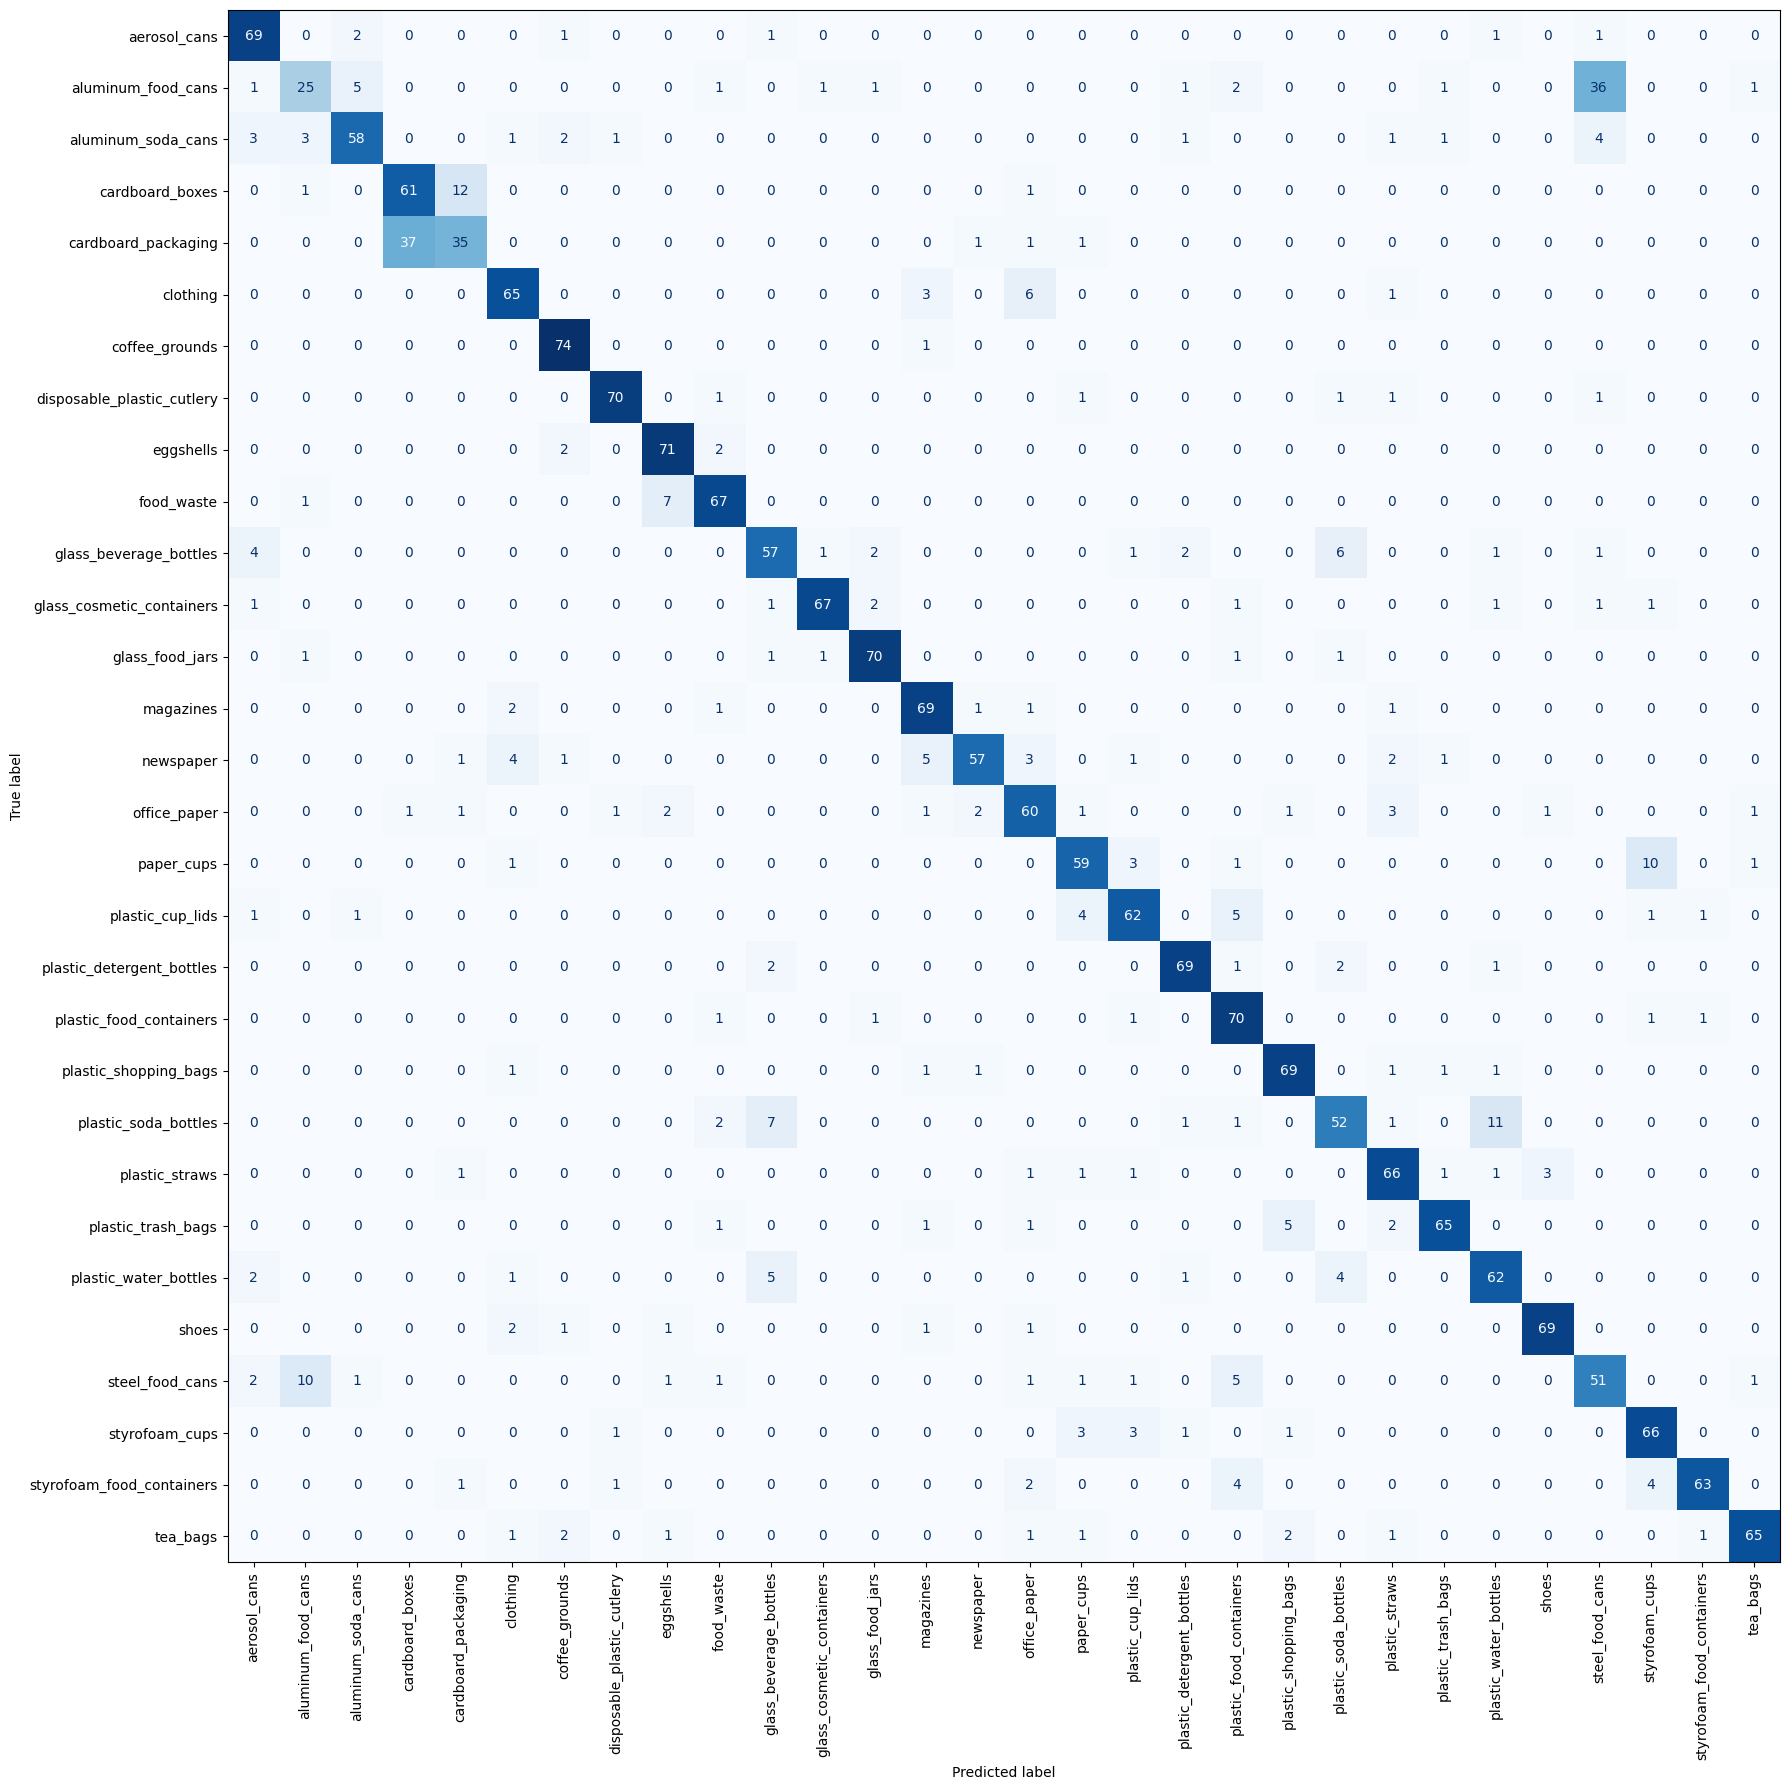

In [8]:
cm = confusion_matrix(
    y_true,
    y_pred
)

fig, ax = plt.subplots(figsize=(18,18))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    xticks_rotation=90,
    ax=ax,
    cmap="Blues",
    colorbar=False
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR/"densenet_confusion_matrix.png",
    dpi=300
)

plt.show()

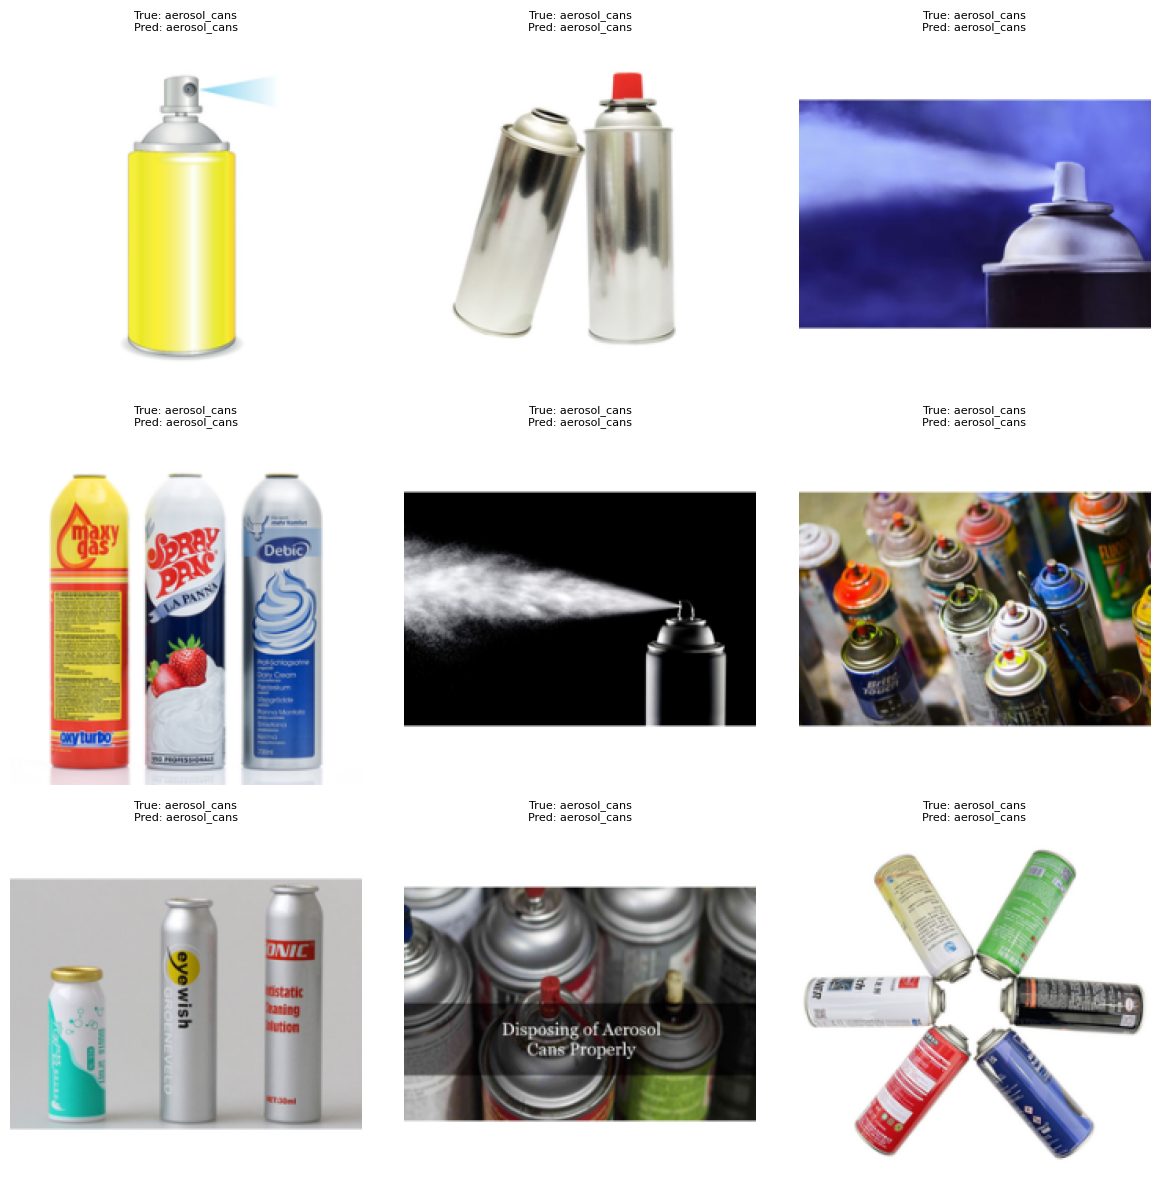

In [9]:
plt.figure(figsize=(12,12))

for images, labels in test_ds.take(1):

    predictions = model.predict(images, verbose=0)

    pred = np.argmax(predictions, axis=1)

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(
            f"True: {CLASS_NAMES[labels[i]]}\n"
            f"Pred: {CLASS_NAMES[pred[i]]}",
            fontsize=8
        )

        plt.axis("off")

plt.tight_layout()

plt.show()

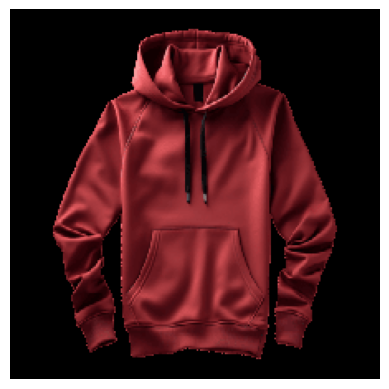

Prediction : clothing
Confidence : 95.23%


In [12]:
#Testing with input image
from tensorflow.keras.preprocessing import image

img_path = r"C:\Users\ASUS\Downloads\sweater-shirt-hoodie-isolated-png.webp"

img = image.load_img(
    img_path,
    target_size=(224,224)
)

img_array = image.img_to_array(img)

plt.imshow(img)
plt.axis("off")
plt.show()

img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)

index = np.argmax(prediction)

confidence = prediction[0][index]

print("Prediction :", CLASS_NAMES[index])
print(f"Confidence : {confidence:.2%}")